In [2]:
pip install pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [5]:
# Load the dataset
df = pd.read_csv('data/bihar_flood_data.csv')

# Display the first 5 rows to ensure it loaded correctly
df.head()

,Date,District,Rainfall_mm,River_Level_m,Danger_Level_m,Flood,Population,Crop_Area_ha
0,2023-11-27,Araria,101.86,5.45,12.0,0,2794130,45827
1,2016-05-25,Purnia,67.95,5.67,12.0,0,1522966,57670
2,2016-01-05,Supaul,62.59,4.82,12.0,0,2428881,90847
3,2017-04-27,Begusarai,46.94,4.81,12.0,0,1743325,88113
4,2022-12-18,Jamui,48.06,4.69,12.0,0,2017991,52990


In [6]:
# 1. Handle the 'Date' column by extracting the Month and Year
# The month is particularly useful because floods are highly seasonal (monsoon)
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year

# Drop the original 'Date' column as we don't need it anymore
df = df.drop('Date', axis=1)

# 2. Handle the 'District' column using Label Encoding
label_encoder = LabelEncoder()
df['District'] = label_encoder.fit_transform(df['District'])

# Check the cleaned data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5600 entries, 0 to 5599
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   District        5600 non-null   int64  
 1   Rainfall_mm     5600 non-null   float64
 2   River_Level_m   5600 non-null   float64
 3   Danger_Level_m  5600 non-null   float64
 4   Flood           5600 non-null   int64  
 5   Population      5600 non-null   int64  
 6   Crop_Area_ha    5600 non-null   int64  
 7   Month           5600 non-null   int32  
 8   Year            5600 non-null   int32  
dtypes: float64(3), int32(2), int64(4)
memory usage: 350.1 KB


In [7]:
# X contains all the features (input variables)
X = df.drop('Flood', axis=1)

# y contains the target variable (output we want to predict)
y = df['Flood']

In [8]:
# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data size: {X_train.shape}")
print(f"Testing data size: {X_test.shape}")

Training data size: (4480, 8)
Testing data size: (1120, 8)


In [9]:
# Initialize the model
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model on the training data
model.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


In [10]:
# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

# Display a detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 93.21%

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       938
           1       0.80      0.78      0.79       182

    accuracy                           0.93      1120
   macro avg       0.88      0.87      0.87      1120
weighted avg       0.93      0.93      0.93      1120



In [ ]:
# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Flood', 'Flood'], 
            yticklabels=['No Flood', 'Flood'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Feature Importance: See which columns were most important for predicting floods
importances = model.feature_importances_
feature_names = X.columns
plt.figure(figsize=(8, 5))
sns.barplot(x=importances, y=feature_names)
plt.title('Feature Importance for Flood Prediction')
plt.show()

Setting Up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import precision_recall_curve, auc

# --- 1. Publication Quality Styling ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'font.size': 12, 
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

# --- 2. Load & Preprocess Data ---
df = pd.read_csv('bihar_flood_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year

# Save a copy for EDA before encoding text to numbers
df_eda = df.copy() 

le = LabelEncoder()
df['District'] = le.fit_transform(df['District'])

X = df.drop(['Flood', 'Date'], axis=1)
y = df['Flood']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- 3. Train Model ---
rf = RandomForestClassifier(n_estimators=200, max_depth=20, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
y_prob = rf.predict_proba(X_test)[:, 1]

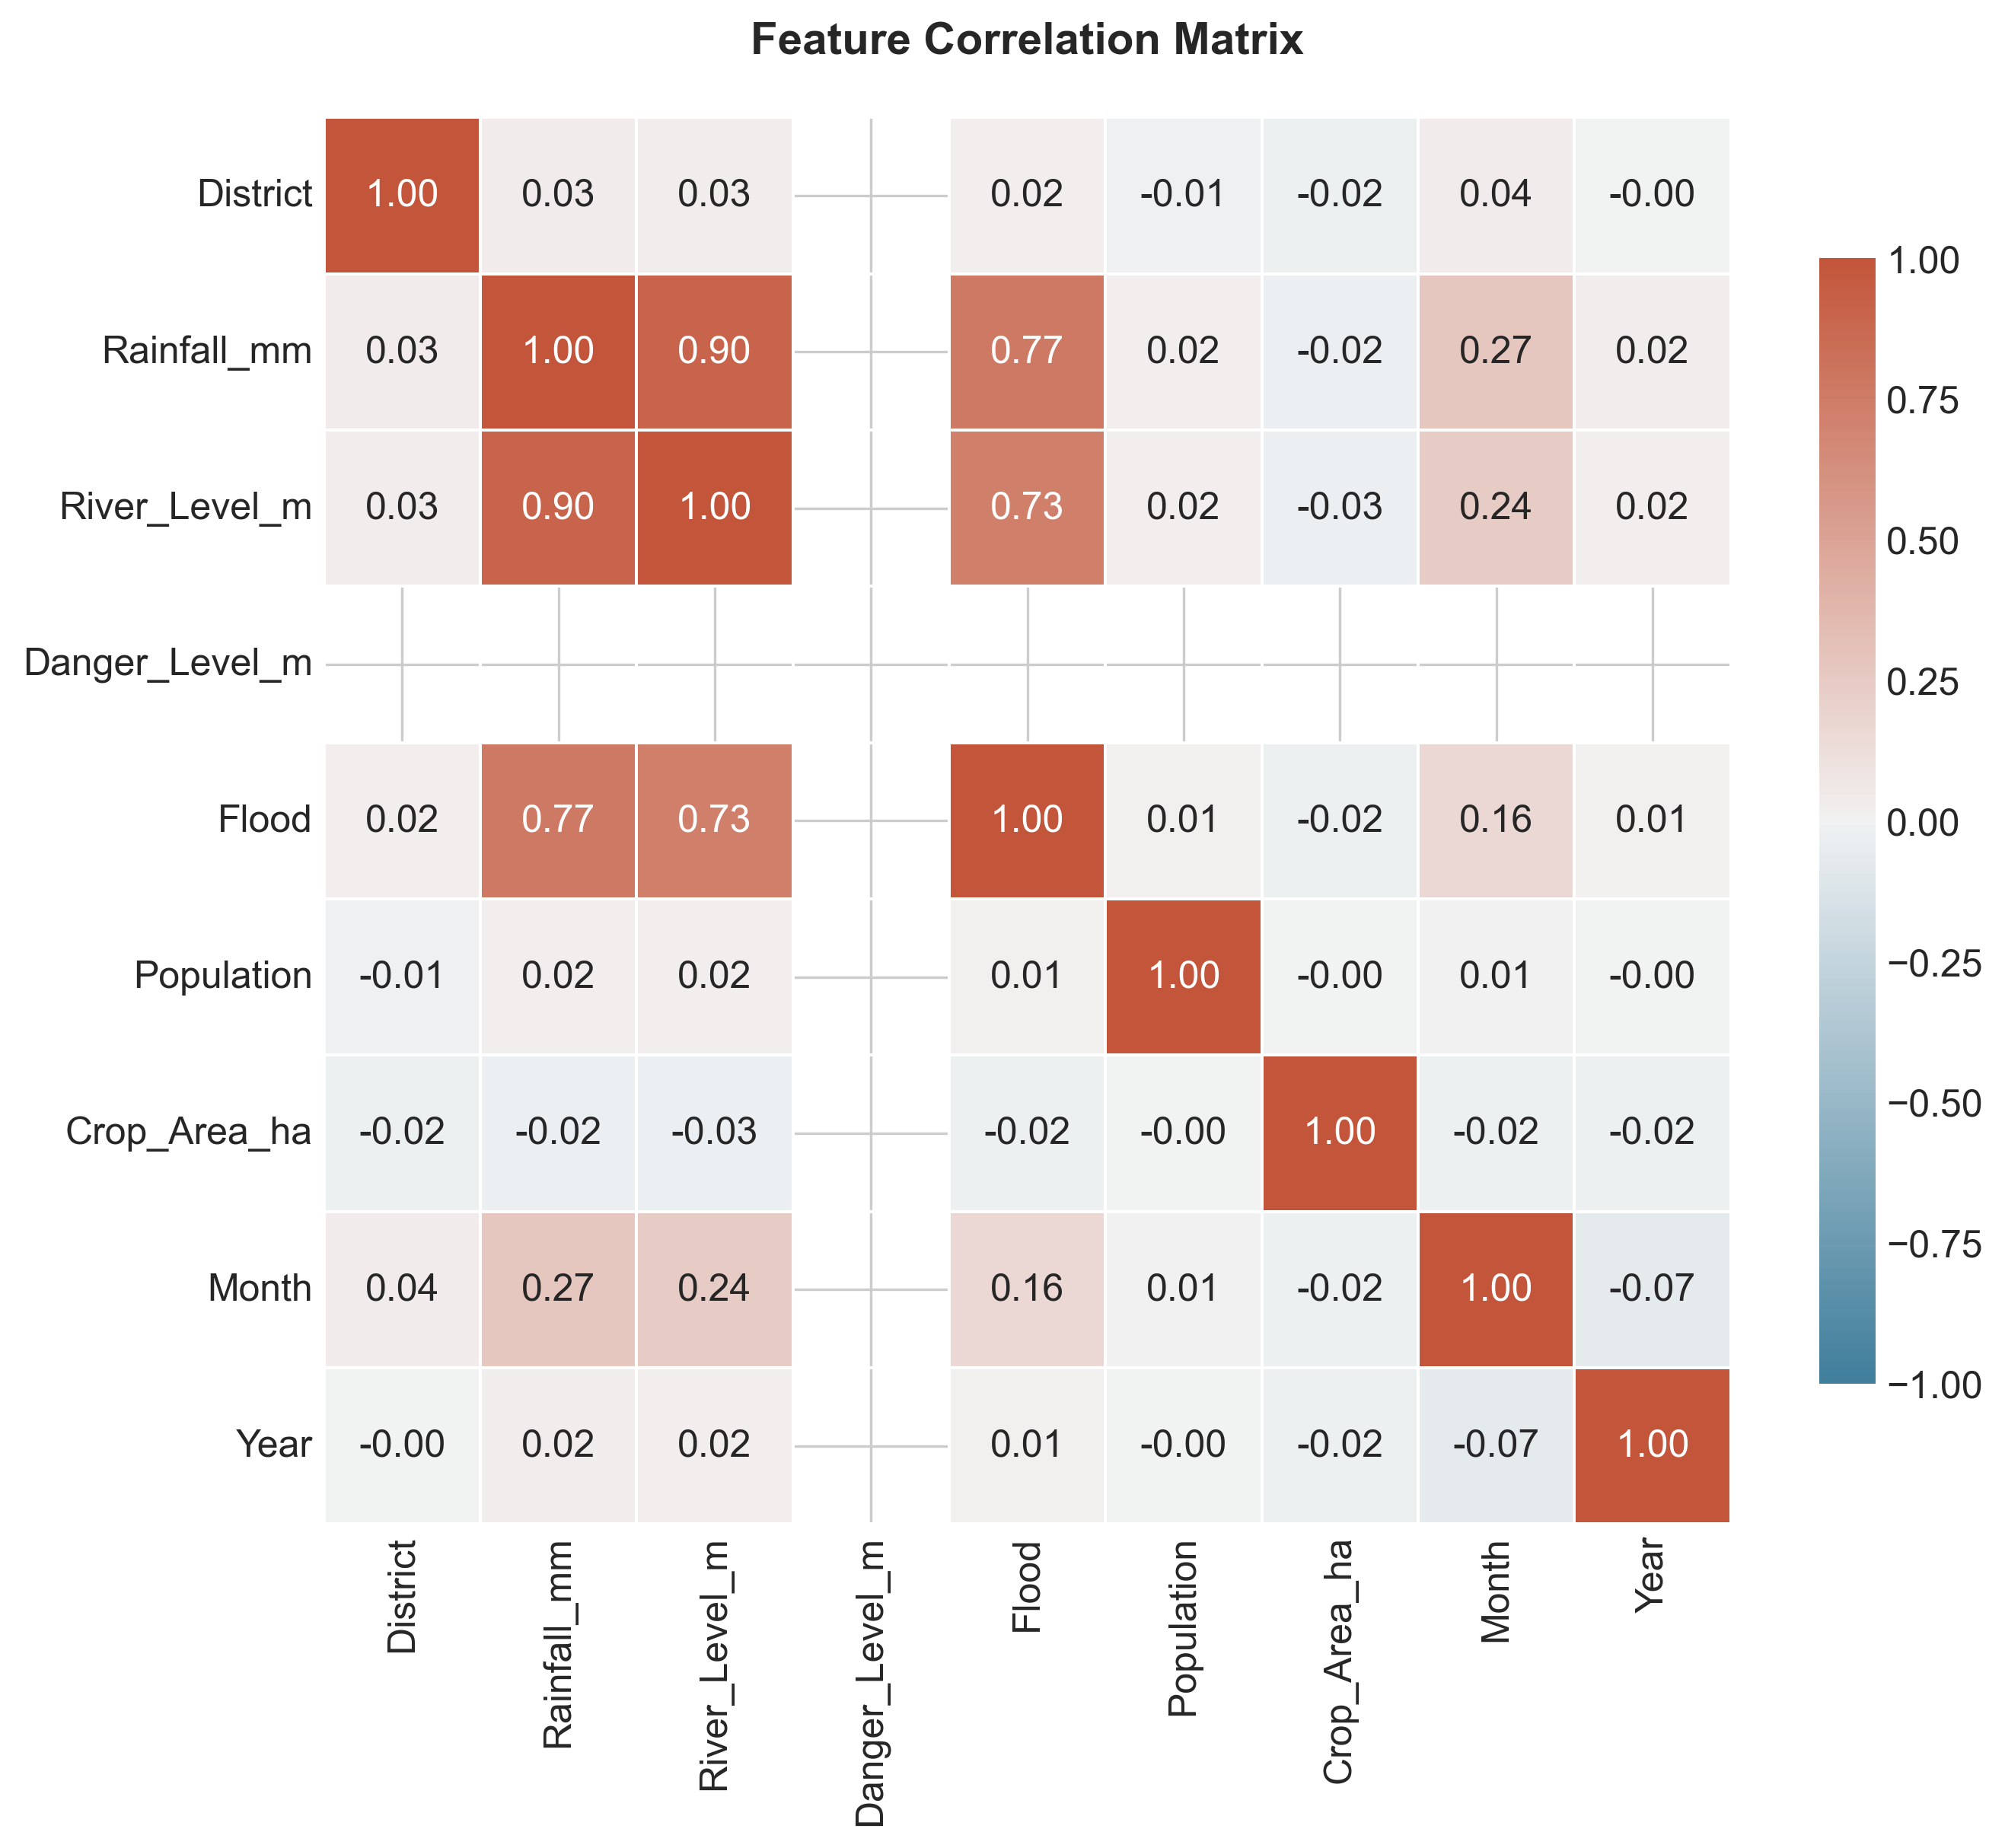

In [2]:
plt.figure(figsize=(10, 8))
# Calculate correlation matrix
corr_matrix = df.drop('Date', axis=1).corr()

# Create a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Plot the heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, 
            square=True, linewidths=.5, cbar_kws={"shrink": .8})

plt.title('Feature Correlation Matrix', pad=20, weight='bold')
plt.savefig('correlation_heatmap.png')
plt.show()

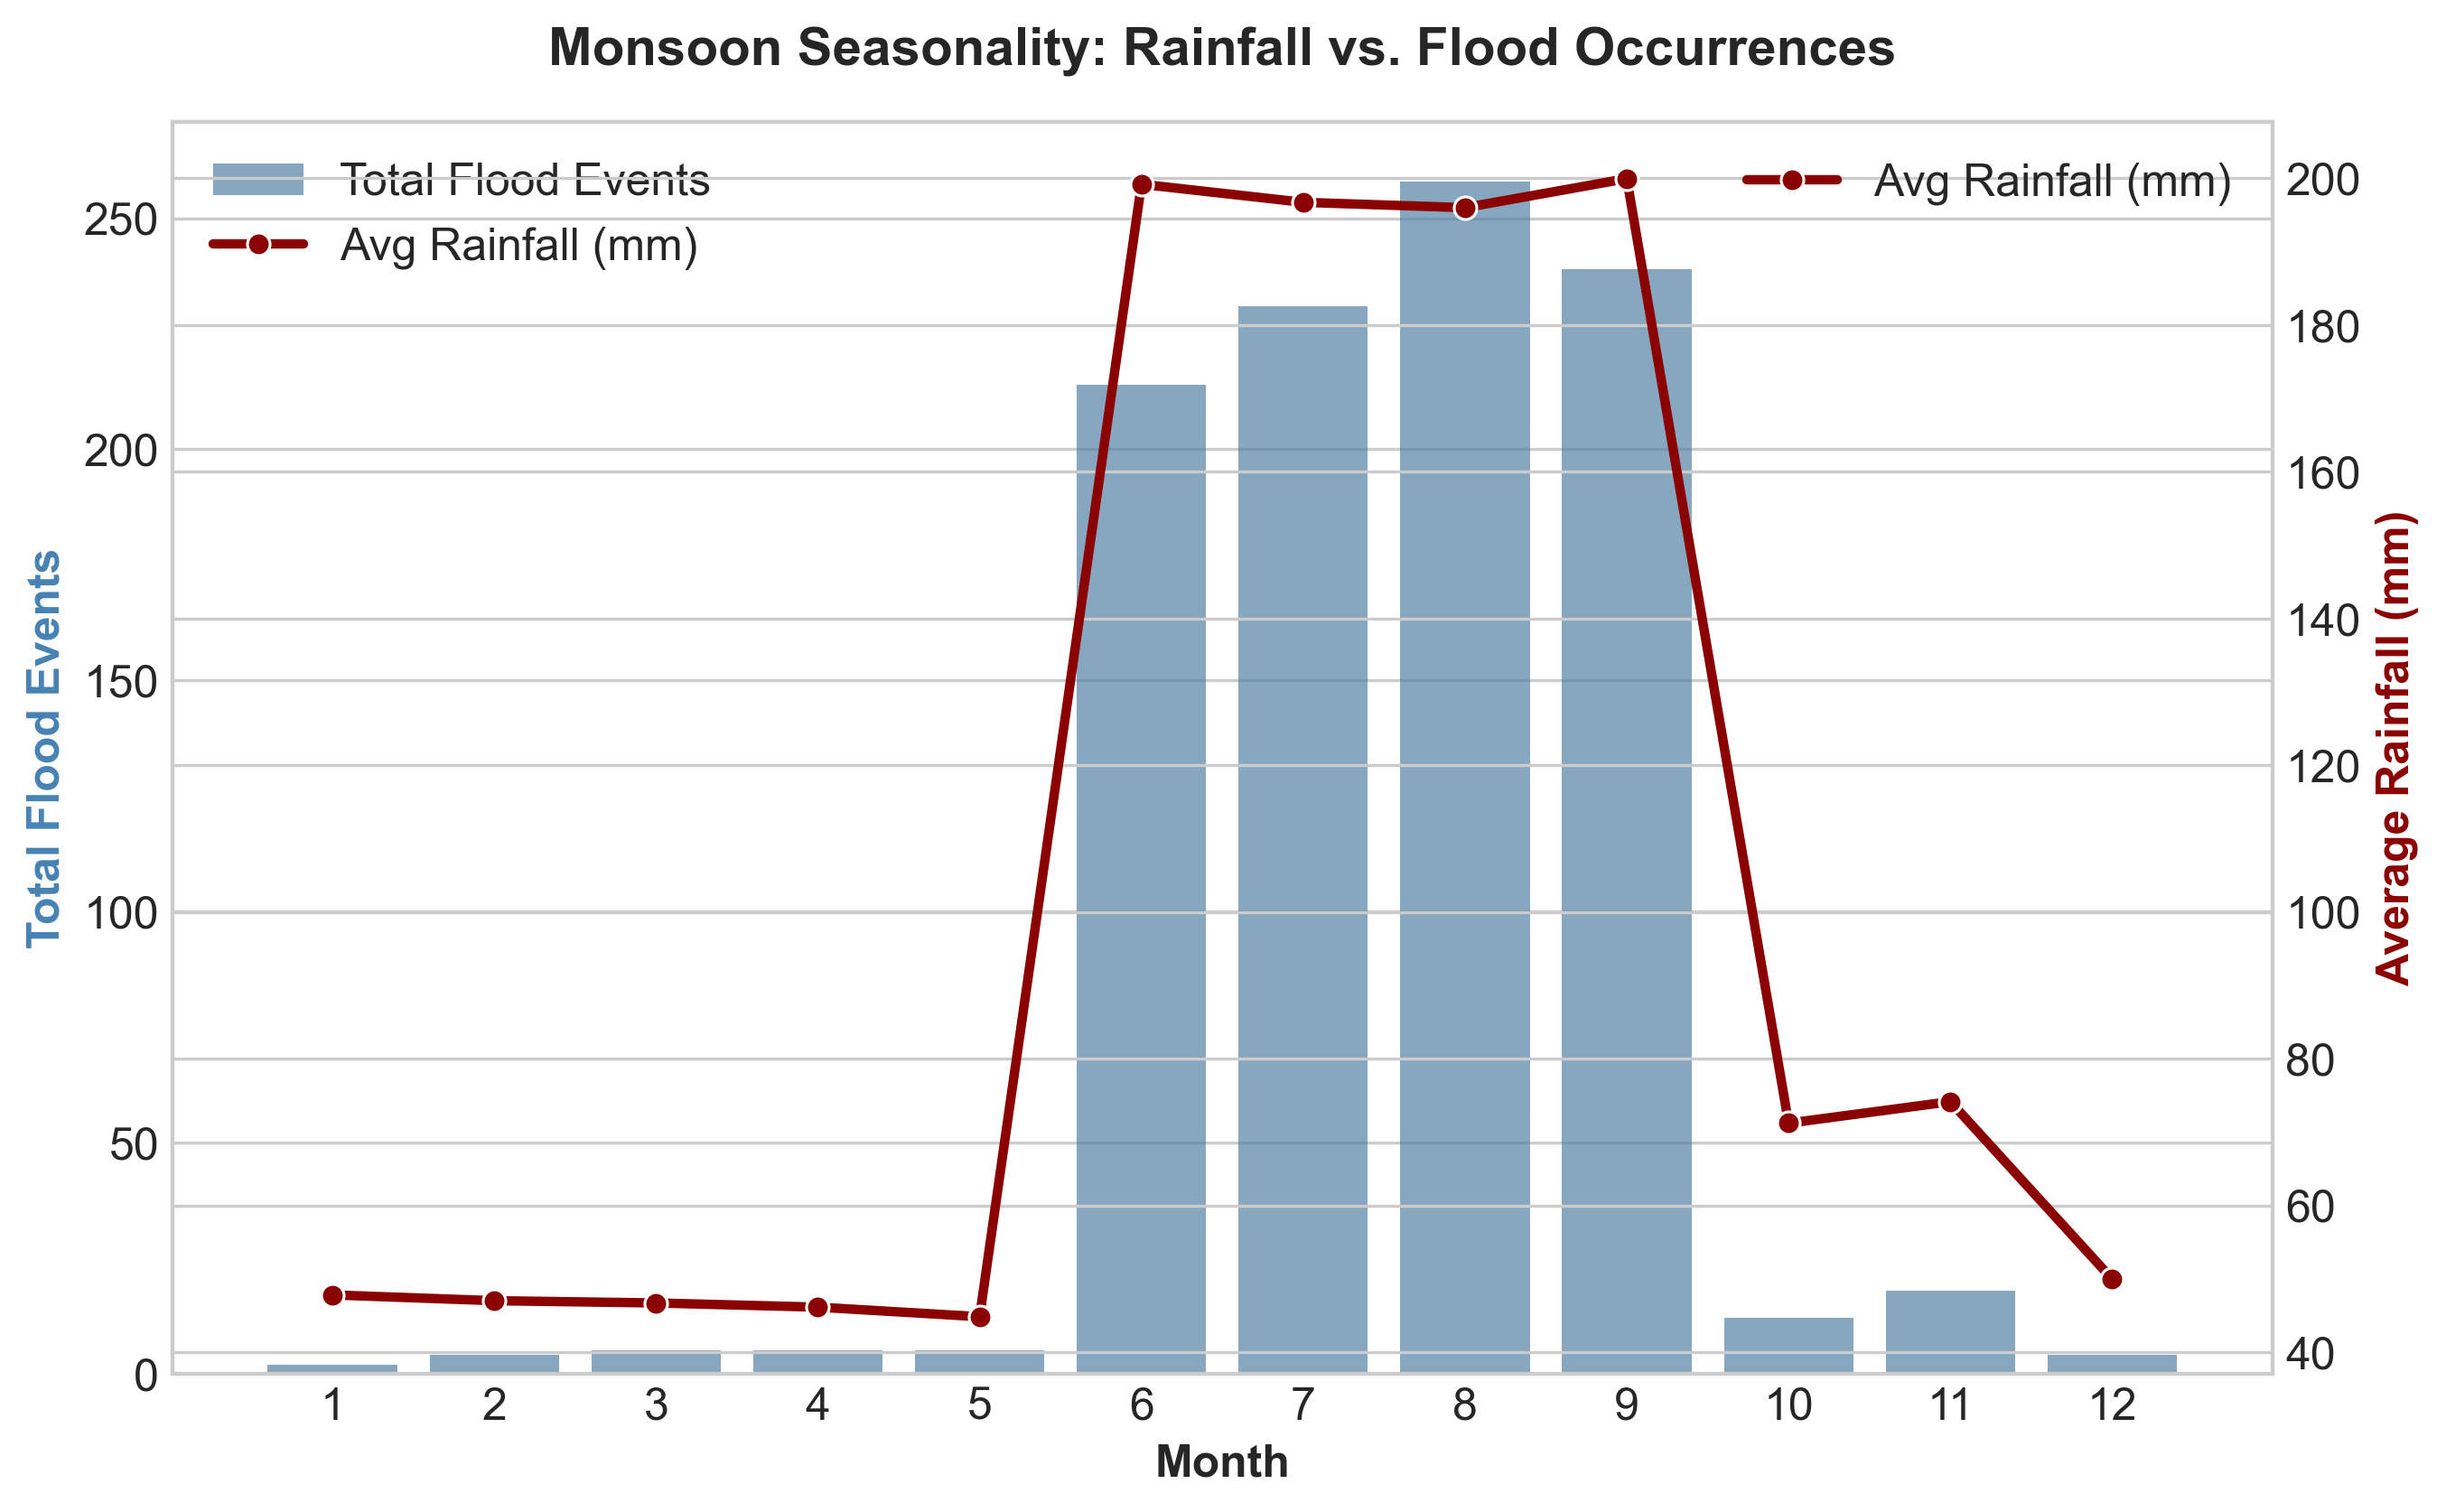

In [3]:
plt.figure(figsize=(10, 6))

# Group by month
monthly_stats = df_eda.groupby('Month').agg(
    Avg_Rainfall=('Rainfall_mm', 'mean'),
    Total_Floods=('Flood', 'sum')
).reset_index()

# Create a twin axis chart
ax1 = plt.gca()
ax2 = ax1.twinx()

# Plot Bars for Floods
sns.barplot(data=monthly_stats, x='Month', y='Total_Floods', ax=ax1, color='steelblue', alpha=0.7, label='Total Flood Events')
# Plot Line for Rainfall
sns.lineplot(data=monthly_stats, x=monthly_stats.index, y='Avg_Rainfall', ax=ax2, color='darkred', marker='o', linewidth=2.5, label='Avg Rainfall (mm)')

ax1.set_xlabel('Month', weight='bold')
ax1.set_ylabel('Total Flood Events', weight='bold', color='steelblue')
ax2.set_ylabel('Average Rainfall (mm)', weight='bold', color='darkred')
plt.title('Monsoon Seasonality: Rainfall vs. Flood Occurrences', pad=15, weight='bold')

# Handle legends
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.savefig('monthly_seasonality.png')
plt.show()

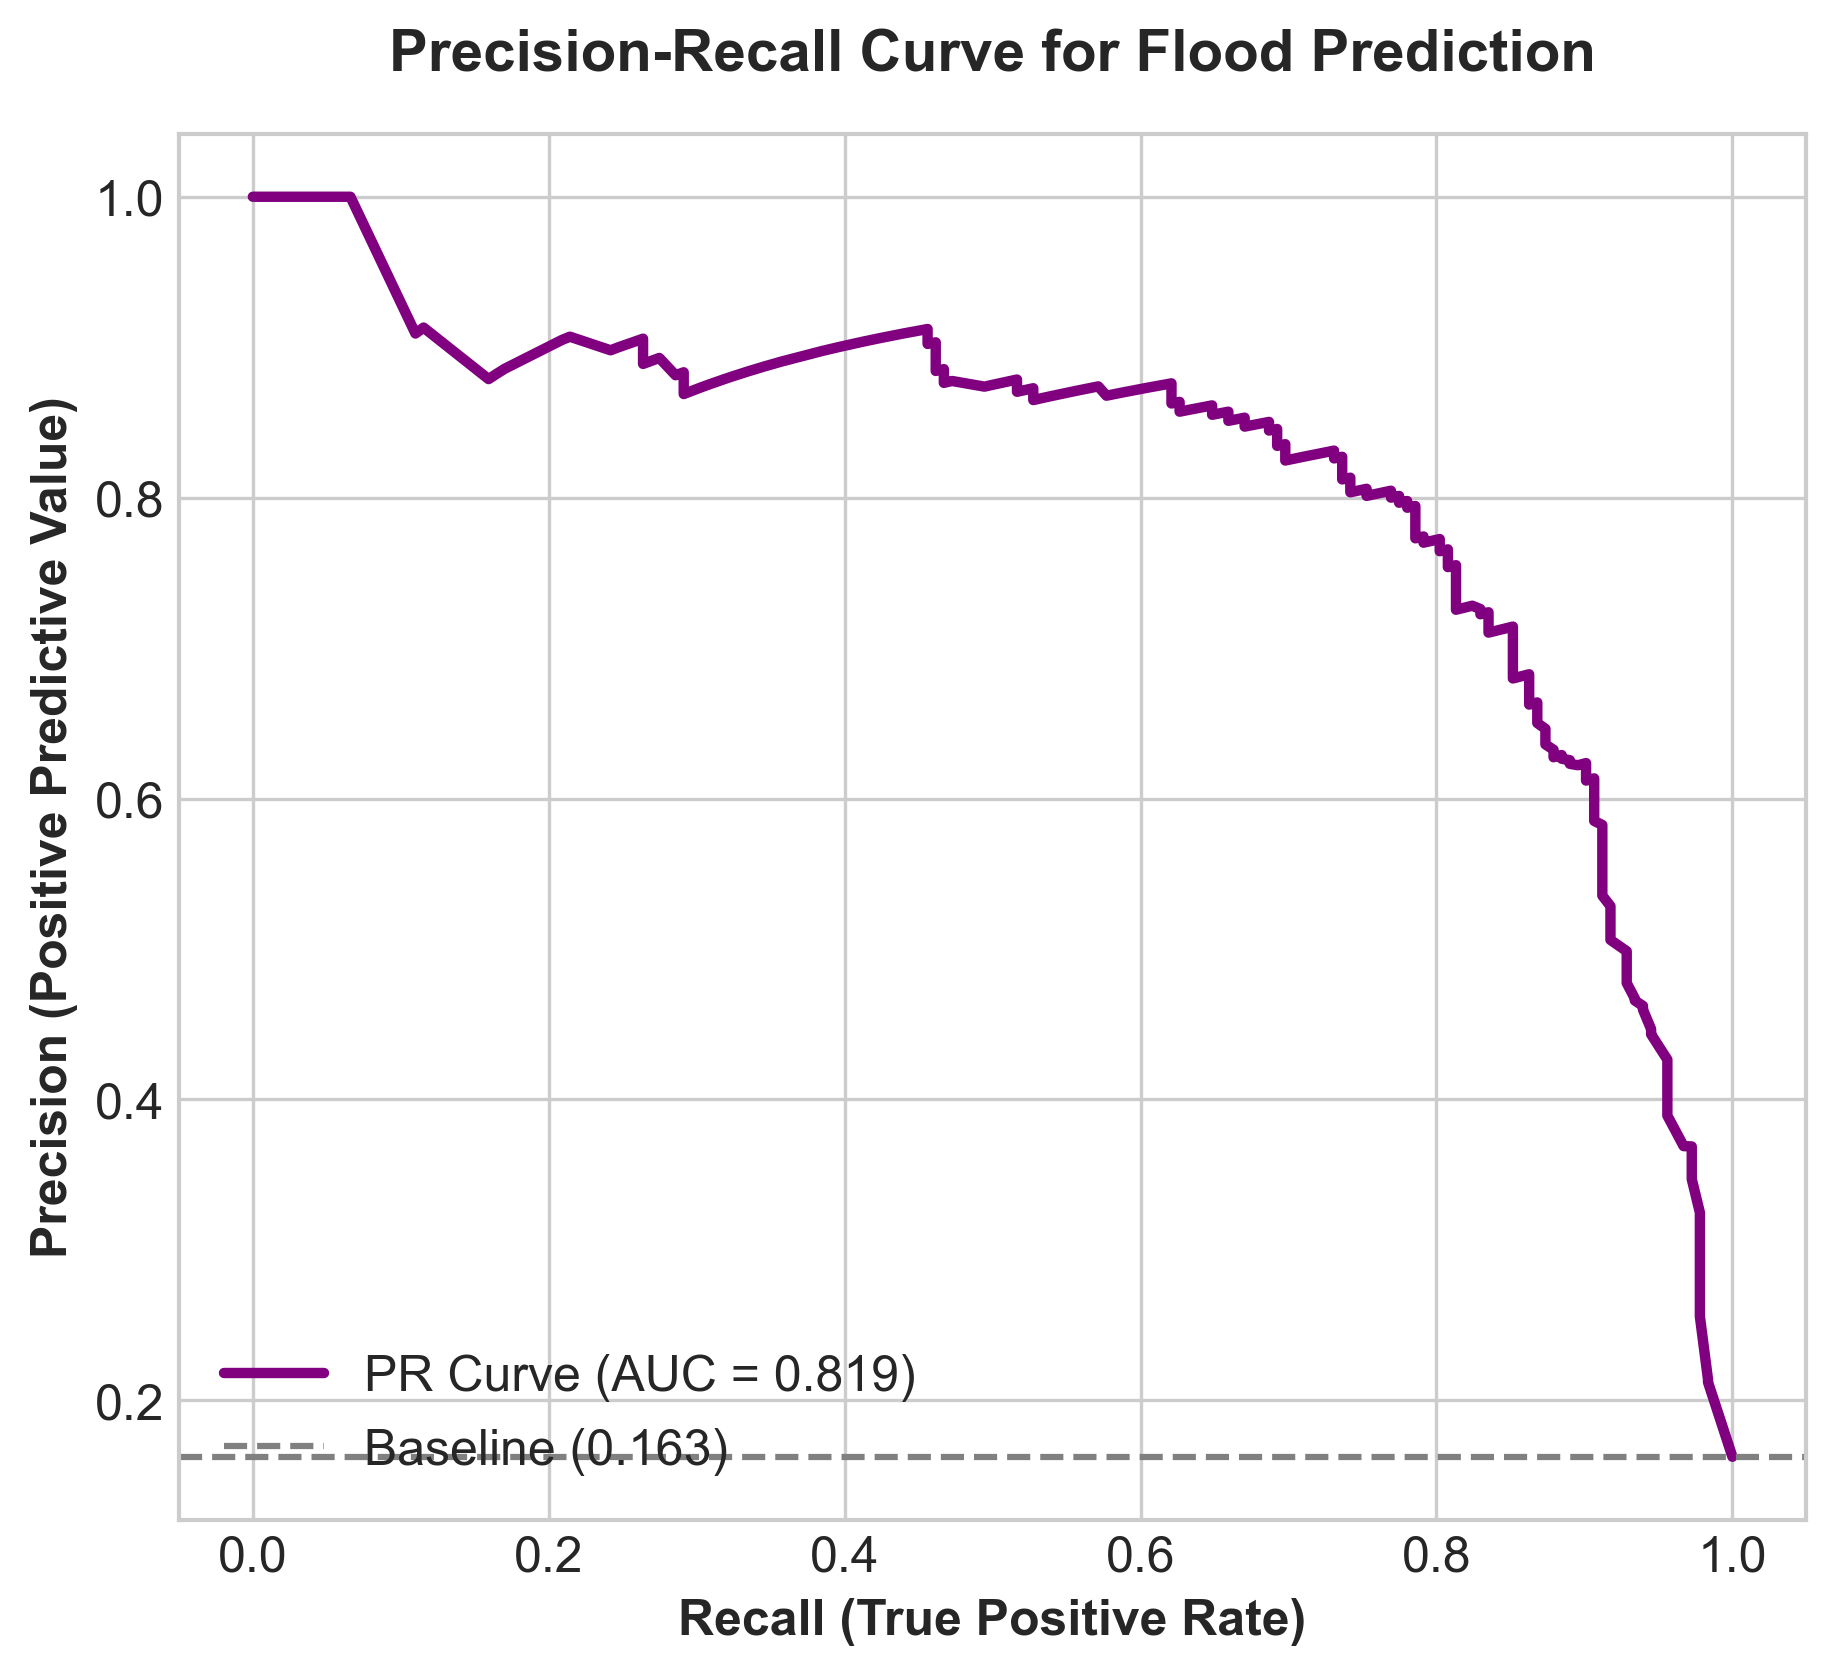

In [4]:
plt.figure(figsize=(7, 6))

# Calculate precision-recall values
precision, recall, _ = precision_recall_curve(y_test, y_prob)
pr_auc = auc(recall, precision)

# Plot the curve
plt.plot(recall, precision, color='purple', lw=2.5, label=f'PR Curve (AUC = {pr_auc:.3f})')

# Baseline is the ratio of positive classes
baseline = len(y_test[y_test == 1]) / len(y_test)
plt.axhline(y=baseline, color='gray', linestyle='--', label=f'Baseline ({baseline:.3f})')

plt.xlabel('Recall (True Positive Rate)', weight='bold')
plt.ylabel('Precision (Positive Predictive Value)', weight='bold')
plt.title('Precision-Recall Curve for Flood Prediction', pad=15, weight='bold')
plt.legend(loc='lower left')

plt.savefig('precision_recall_curve.png')
plt.show()

C:\Users\Vansh Agrawal\AppData\Local\Temp\ipykernel_41776\2732214066.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=district_floods.values, y=district_floods.index, palette='Reds_r')


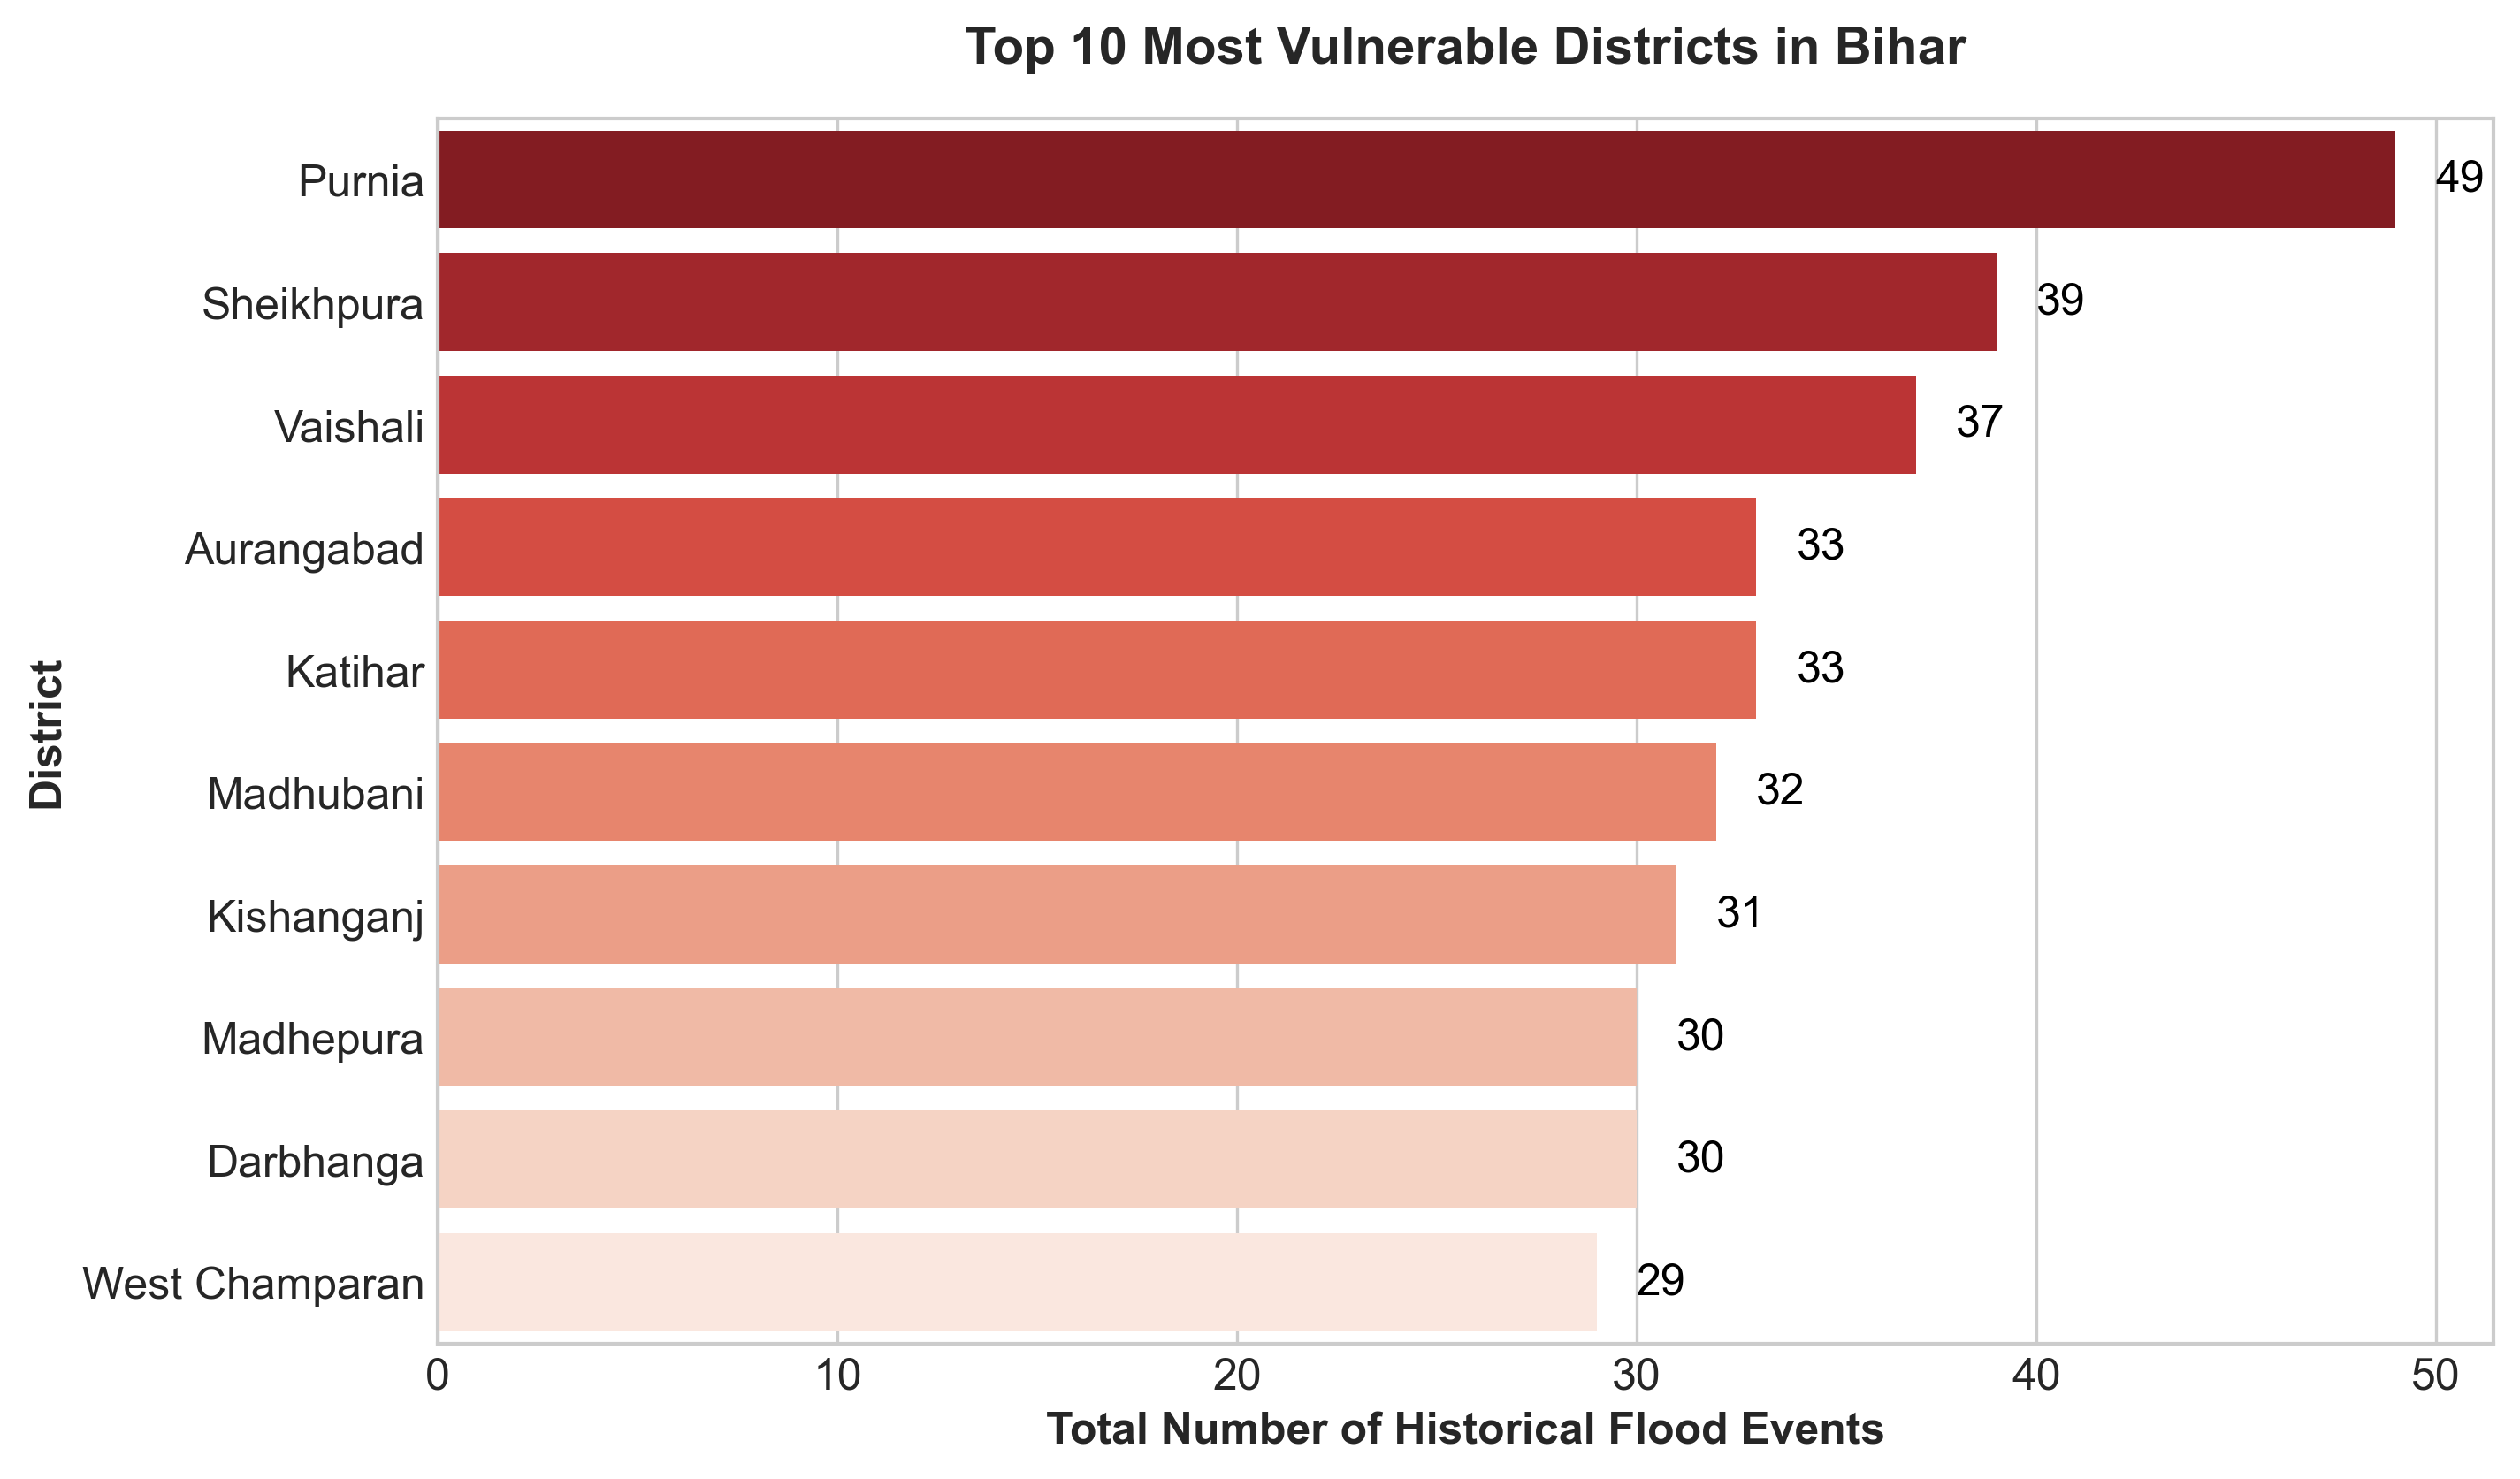

In [5]:
plt.figure(figsize=(10, 6))

# Count floods per district
district_floods = df_eda[df_eda['Flood'] == 1].groupby('District').size().sort_values(ascending=False).head(10)

# Plot
sns.barplot(x=district_floods.values, y=district_floods.index, palette='Reds_r')

plt.xlabel('Total Number of Historical Flood Events', weight='bold')
plt.ylabel('District', weight='bold')
plt.title('Top 10 Most Vulnerable Districts in Bihar', pad=15, weight='bold')

# Add values on the bars
for i, v in enumerate(district_floods.values):
    plt.text(v + 1, i, str(v), color='black', va='center')

plt.savefig('vulnerable_districts.png')
plt.show()

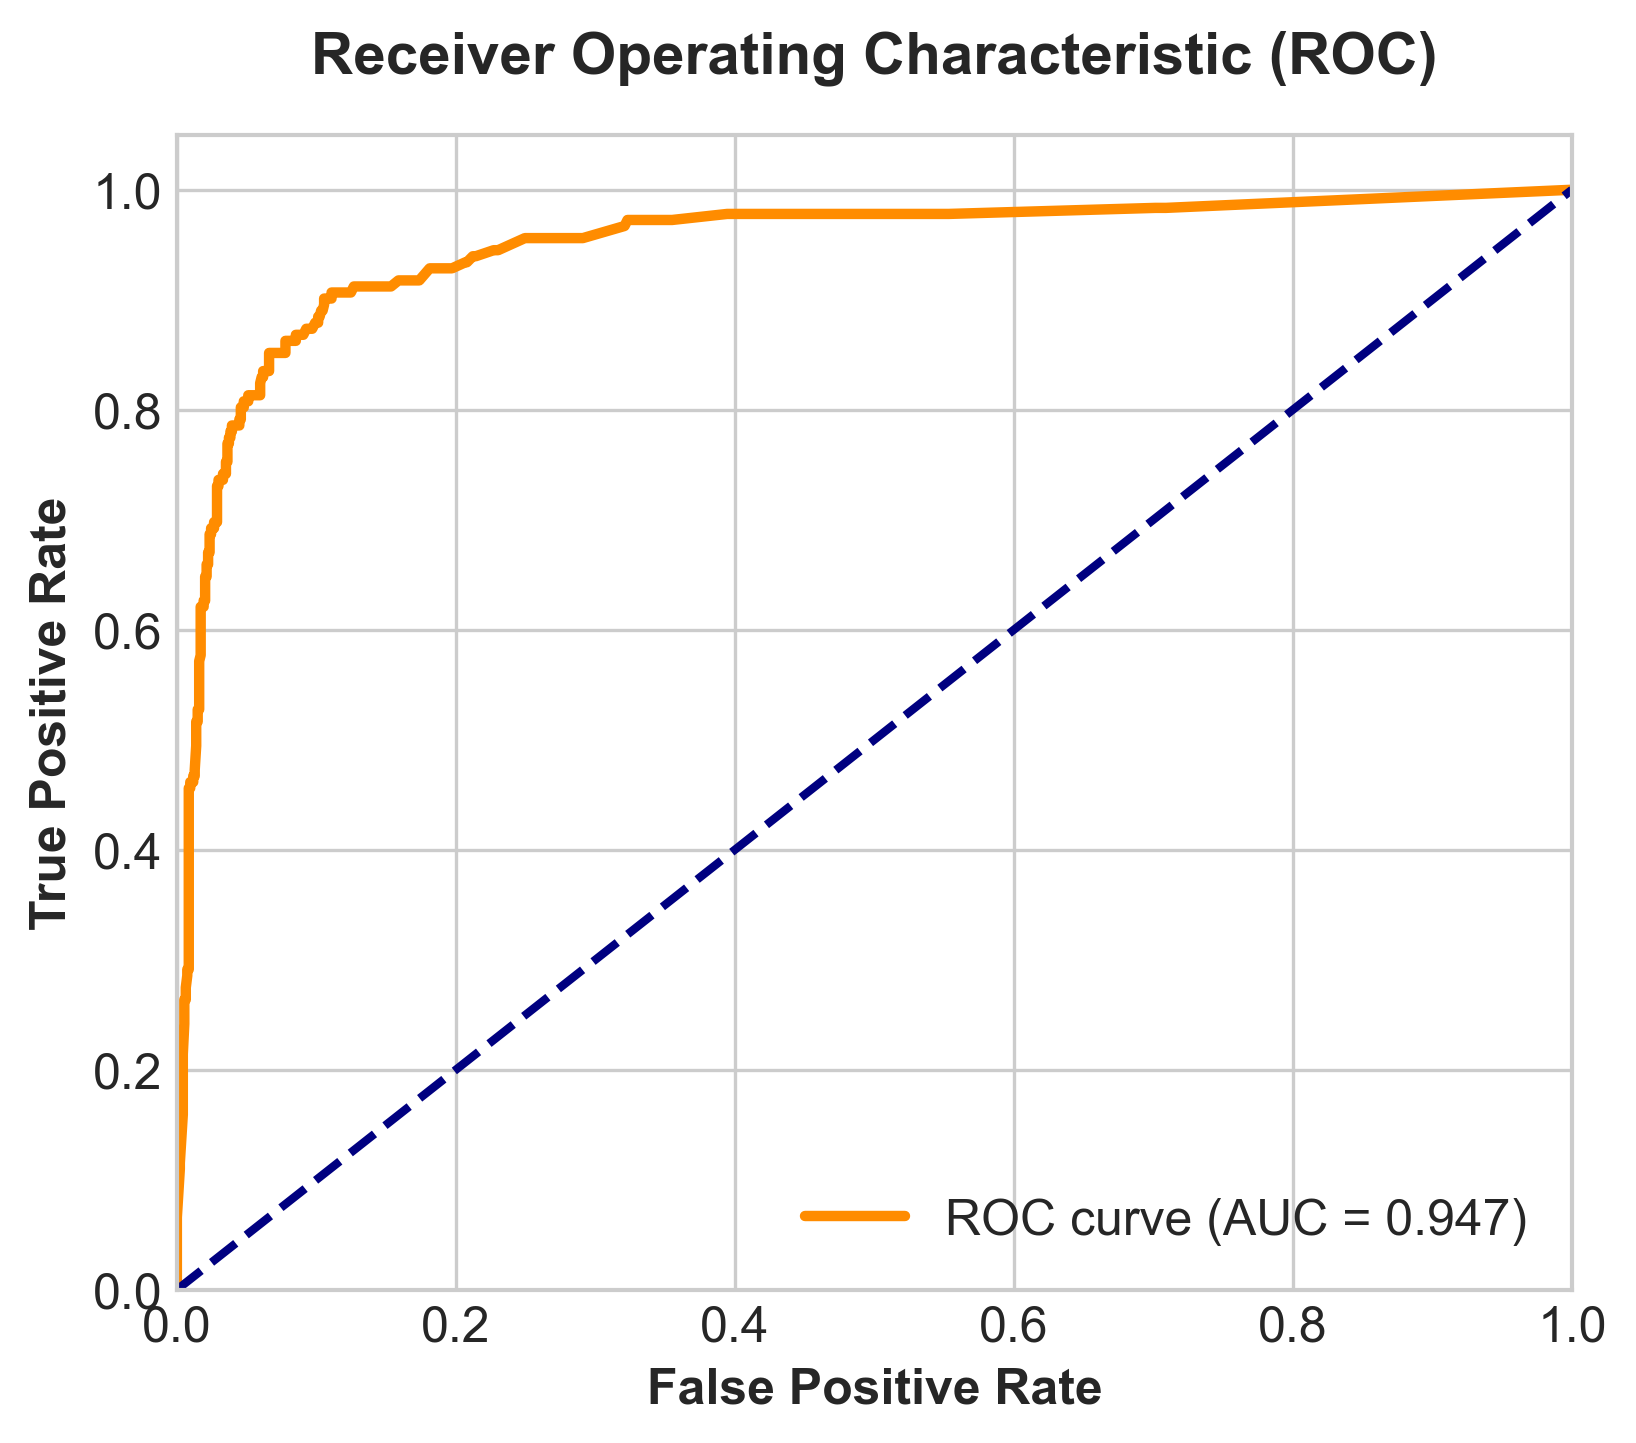

In [6]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(6, 5))
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', weight='bold')
plt.ylabel('True Positive Rate', weight='bold')
plt.title('Receiver Operating Characteristic (ROC)', pad=15, weight='bold')
plt.legend(loc="lower right")

plt.savefig('roc_curve.png')
plt.show()

C:\Users\Vansh Agrawal\AppData\Local\Temp\ipykernel_41776\2926897969.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=[features[i] for i in indices], palette='viridis')


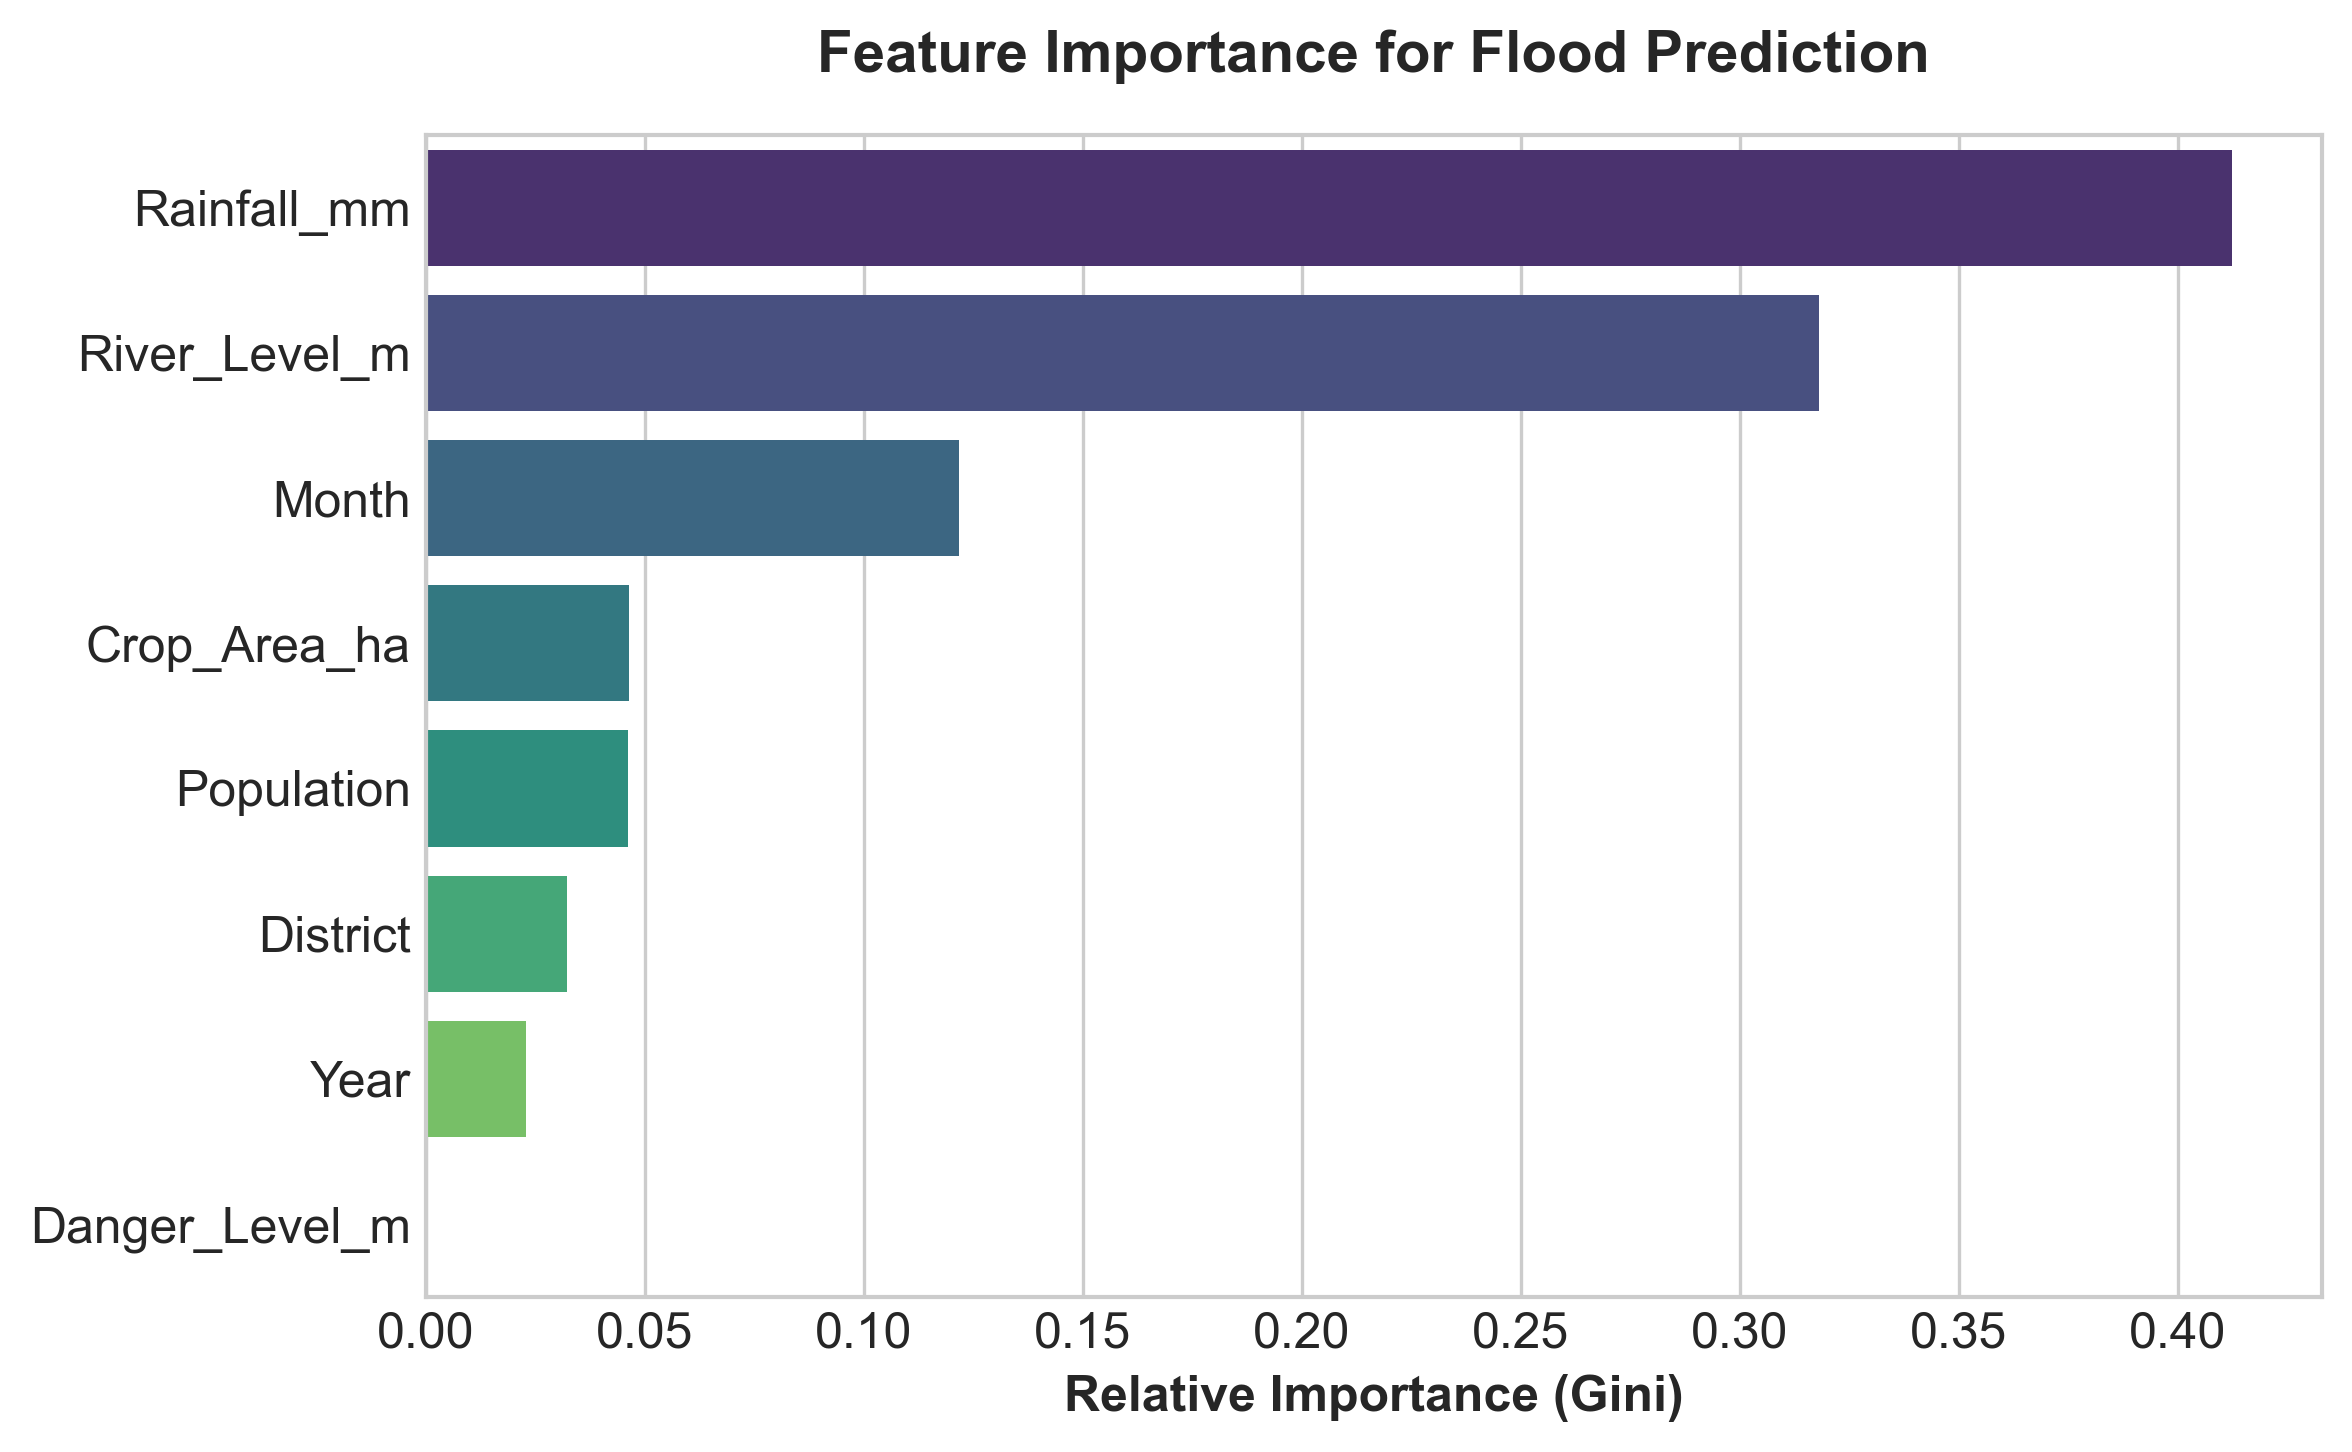

In [8]:
plt.figure(figsize=(8, 5))

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns

sns.barplot(x=importances[indices], y=[features[i] for i in indices], palette='viridis')

plt.title('Feature Importance for Flood Prediction', pad=15, weight='bold')
plt.xlabel('Relative Importance (Gini)', weight='bold')
plt.tight_layout()

plt.savefig('feature_importance.png')
plt.show()

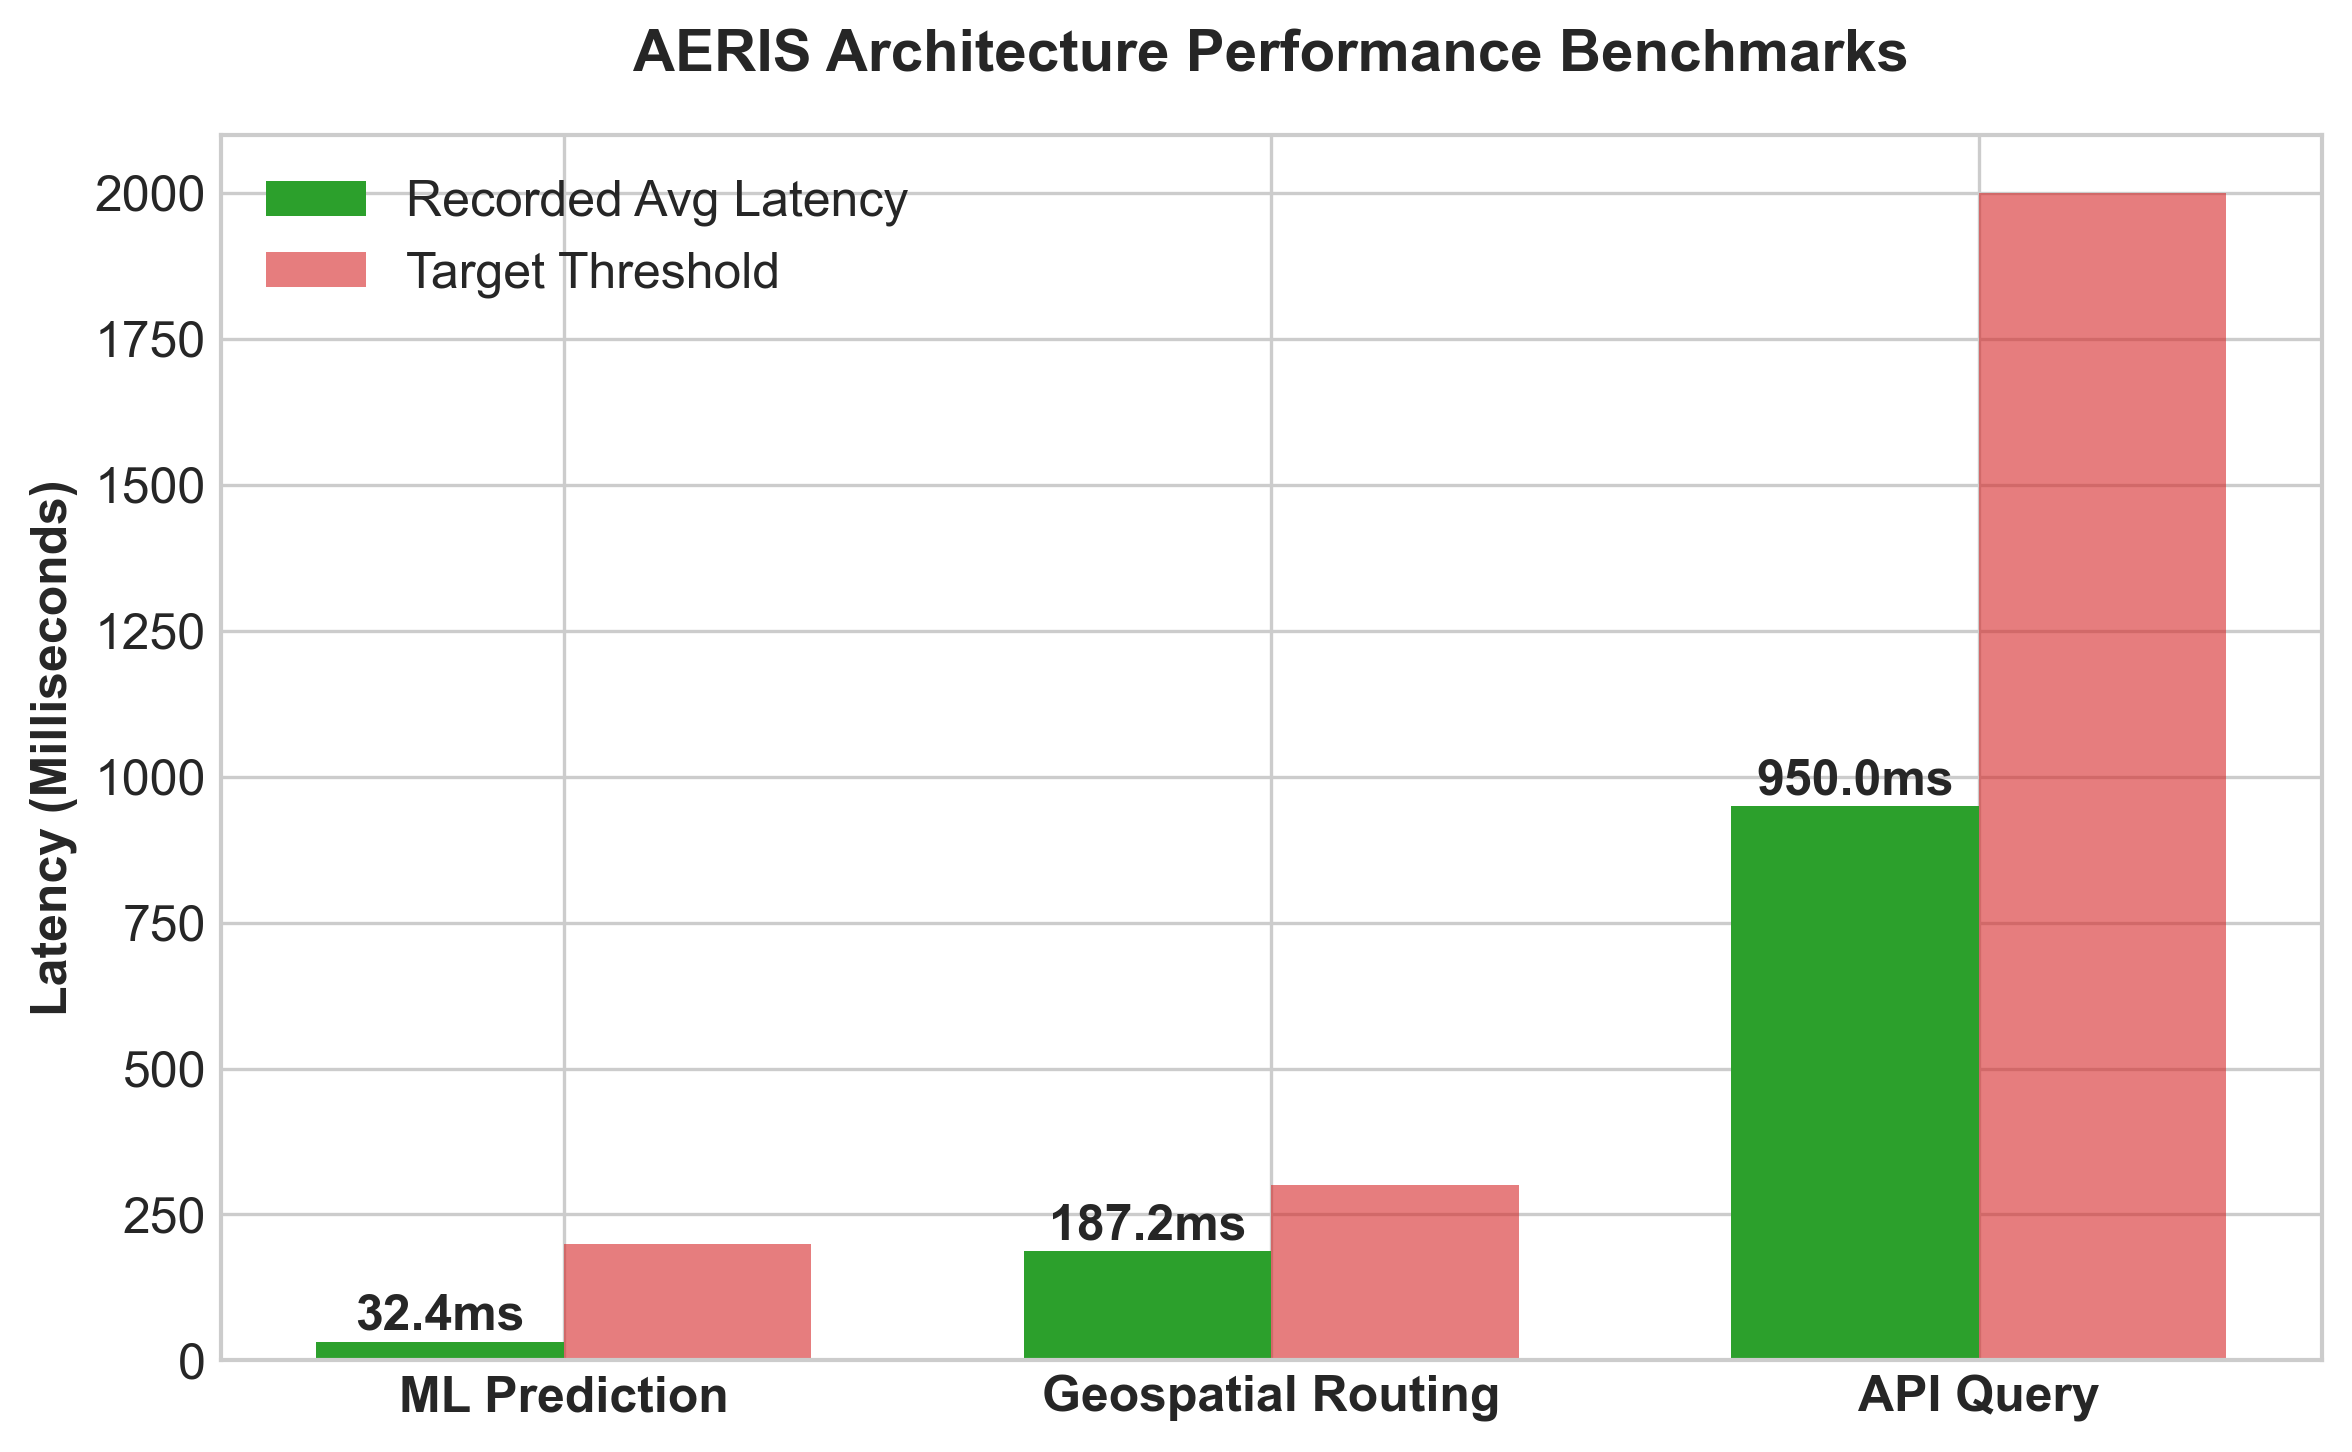

In [9]:
# System performance data from the paper
labels = ['ML Prediction', 'Geospatial Routing', 'API Query']
recorded = [32.4, 187.2, 950.0]  # ms
targets = [200.0, 300.0, 2000.0] # ms target thresholds

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, recorded, width, label='Recorded Avg Latency', color='#2ca02c')
rects2 = ax.bar(x + width/2, targets, width, label='Target Threshold', color='#d62728', alpha=0.6)

ax.set_ylabel('Latency (Milliseconds)', weight='bold')
ax.set_title('AERIS Architecture Performance Benchmarks', pad=15, weight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, weight='bold')
ax.legend()

# Add exact numbers on top of the 'Recorded' bars
for i, v in enumerate(recorded):
    ax.text(i - width/2, v + 20, f'{v}ms', ha='center', weight='bold')

plt.tight_layout()
plt.savefig('latency_benchmark.png')
plt.show()

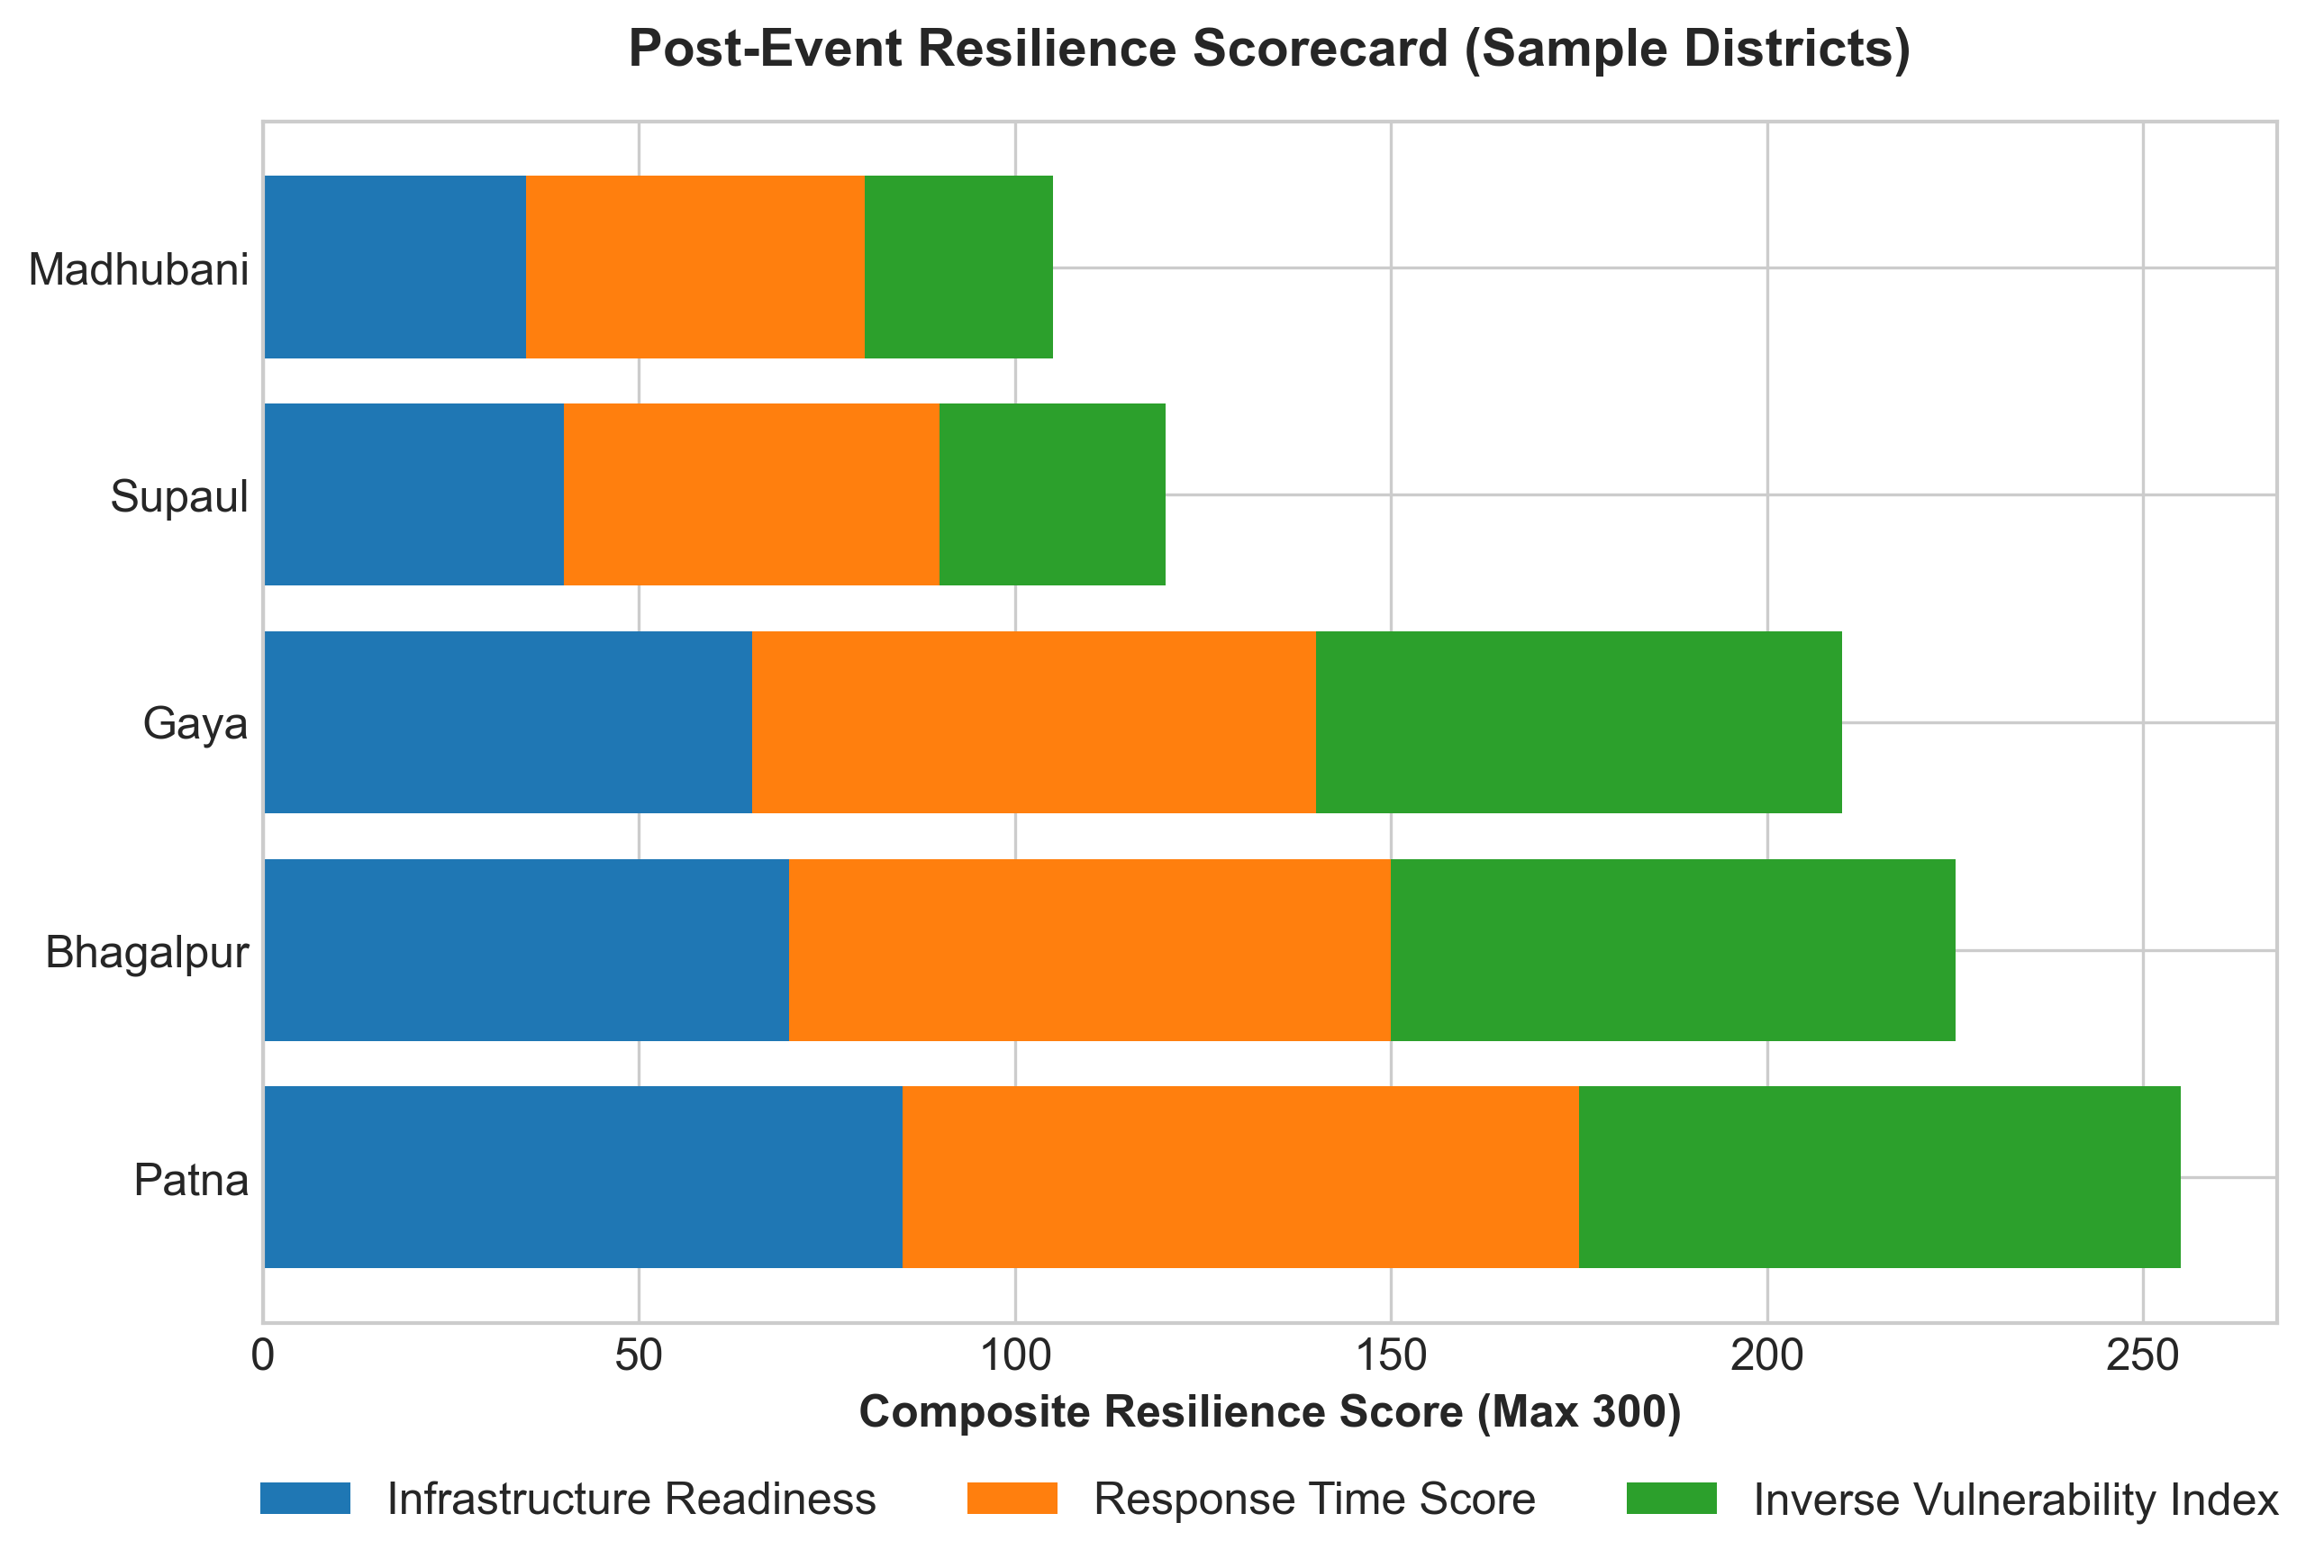

In [10]:
# Simulated resilience data for 5 sample districts as described in your paper
districts_show = ['Patna', 'Bhagalpur', 'Gaya', 'Supaul', 'Madhubani']
infra = [85, 70, 65, 40, 35]       # Infrastructure Readiness
response = [90, 80, 75, 50, 45]    # Response Time Score
vuln_inv = [80, 75, 70, 30, 25]    # Inverse Vulnerability (Higher is better)

fig, ax = plt.subplots(figsize=(9, 6))

# Stacked Horizontal Bar Chart
ax.barh(districts_show, infra, label='Infrastructure Readiness', color='#1f77b4')
ax.barh(districts_show, response, left=infra, label='Response Time Score', color='#ff7f0e')
ax.barh(districts_show, vuln_inv, left=np.array(infra)+np.array(response), label='Inverse Vulnerability Index', color='#2ca02c')

ax.set_xlabel('Composite Resilience Score (Max 300)', weight='bold')
ax.set_title('Post-Event Resilience Scorecard (Sample Districts)', pad=15, weight='bold')

# Move legend below the graph
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=3)

plt.tight_layout()
plt.savefig('resilience_scorecard.png')
plt.show()